# 신경망 모델 훈련

<table align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/rickiepark/hg-mldl/blob/master/7-3.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />구글 코랩에서 실행하기</a>
  </td>
</table>

In [33]:
import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import tensorflow as tf
import keras

keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

## 손실 곡선

In [34]:
(train_input, train_target), (test_input, test_target) = keras.datasets.fashion_mnist.load_data()
train_scaled, test_scaled = train_input/255.0, test_input/255.0
train_scaled, val_scaled, train_target, val_target = train_test_split(
    train_scaled, train_target, test_size=0.2, random_state=42
)
print(train_scaled.shape, train_target.shape)
print(val_scaled.shape, val_target.shape)
print(test_scaled.shape, test_target.shape)

(48000, 28, 28) (48000,)
(12000, 28, 28) (12000,)
(10000, 28, 28) (10000,)


In [35]:
def model_fn(a_layer=None):
    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(28,28)))
    model.add(keras.layers.Flatten())
    model.add(keras.layers.Dense(100, activation='relu'))
    if a_layer:
        model.add(a_layer)
    model.add(keras.layers.Dense(10, activation='softmax'))
    return model

model = model_fn()
model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_12 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_scaled, train_target, epochs=5, verbose='auto')
print(history.history.keys())

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 683us/step - accuracy: 0.8112 - loss: 0.5311
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 678us/step - accuracy: 0.8586 - loss: 0.3903
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 663us/step - accuracy: 0.8729 - loss: 0.3523
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 679us/step - accuracy: 0.8810 - loss: 0.3306
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 701us/step - accuracy: 0.8873 - loss: 0.3136
dict_keys(['accuracy', 'loss'])


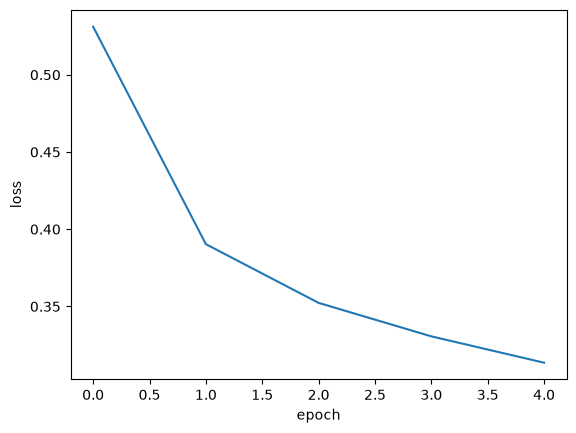

In [37]:
plt.plot(history.history['loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

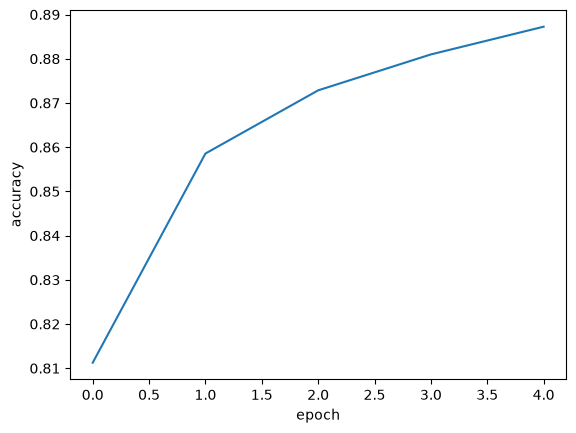

In [38]:
plt.plot(history.history['accuracy'])
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.show()

In [39]:
model = model_fn()
model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_scaled, train_target, epochs=20, verbose='auto')

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 684us/step - accuracy: 0.8109 - loss: 0.5377
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 669us/step - accuracy: 0.8565 - loss: 0.3983
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 678us/step - accuracy: 0.8706 - loss: 0.3585
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 709us/step - accuracy: 0.8797 - loss: 0.3346
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 671us/step - accuracy: 0.8876 - loss: 0.3172
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 724us/step - accuracy: 0.8928 - loss: 0.3023
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 666us/step - accuracy: 0.8974 - loss: 0.2908
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 754us/step - accuracy: 0.9021 - loss: 0.2814
Epoch 9/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 695us/step - accuracy: 0.9056 - loss: 0.2727
Epoch 10/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 686us/step - accuracy: 0.9085 - loss: 0.2651
Epoch 11/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 697us/step - accuracy: 0.9116 - loss: 0.2591
Epoch 12

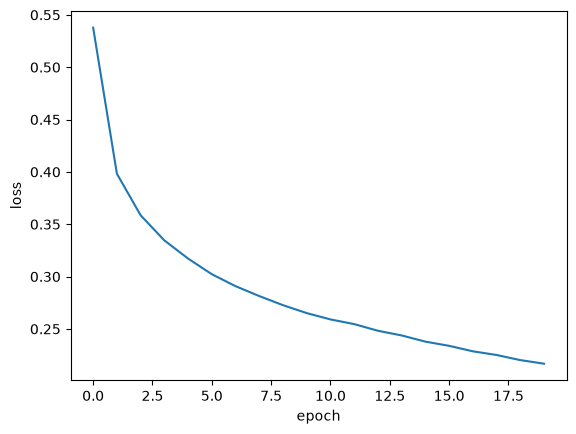

In [40]:
plt.plot(history.history['loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

## 검증 손실

In [41]:
model = model_fn()
model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy']) # optimizer='rmsprop'
history = model.fit(train_scaled, train_target, epochs=20, verbose=0, validation_data=(val_scaled, val_target))
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


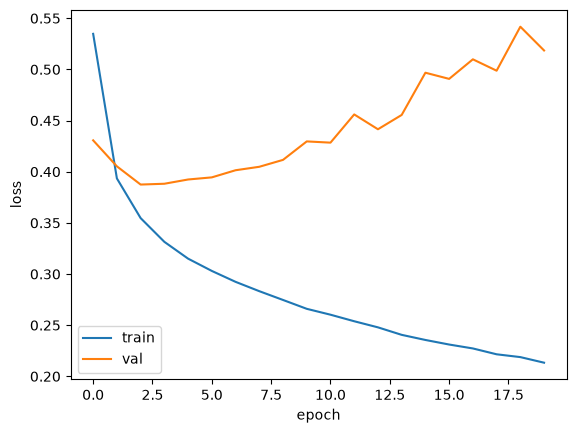

In [42]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

In [43]:
model = model_fn()
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_scaled, train_target, epochs=20, verbose=0, validation_data=(val_scaled, val_target))

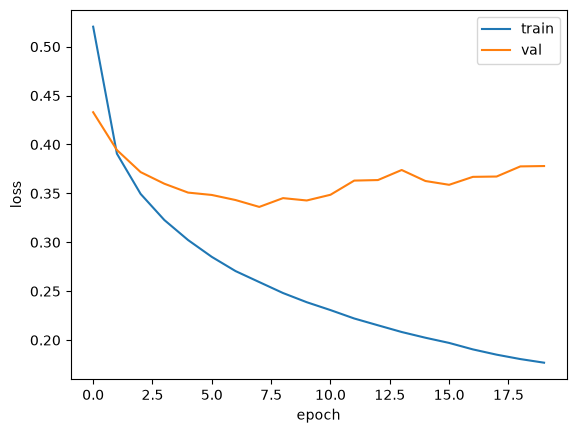

In [44]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

## 드롭아웃

In [45]:
model = model_fn(keras.layers.Dropout(0.3))
model.summary()

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_16 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_scaled, train_target, epochs=20, verbose=0, validation_data=(val_scaled, val_target))

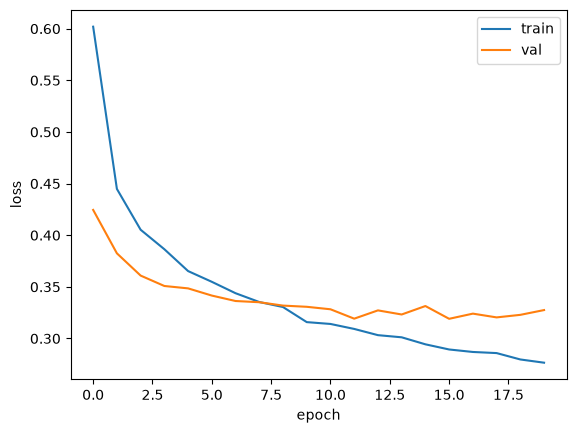

In [47]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

## 모델 저장과 복원

In [48]:
model = model_fn(keras.layers.Dropout(0.3))
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_scaled, train_target, epochs=10, verbose=0, validation_data=(val_scaled, val_target)) # epochs: 20->10

In [49]:
model_whole_path = './model-whole.keras'
model_weights_path = './model.weights.h5'

if not os.path.exists(model_whole_path):
    model.save(model_whole_path)

if not os.path.exists(model_weights_path):
    model.save_weights(model_weights_path)

In [50]:
model = model_fn(keras.layers.Dropout(0.3))
model.load_weights(model_weights_path)

In [51]:
val_labels = np.argmax(model.predict(val_scaled), axis=-1)
print(np.mean(val_labels == val_target))

375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 435us/step
0.8796666666666667


In [52]:
model = keras.models.load_model(model_whole_path)
model.evaluate(val_scaled, val_target)

375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 569us/step - accuracy: 0.8797 - loss: 0.3298


[0.32979816198349, 0.8796666860580444]

## 콜백

In [53]:
model = model_fn(keras.layers.Dropout(0.3))
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

best_model_path = './best-model.keras'
checkpoint_cb = keras.callbacks.ModelCheckpoint(best_model_path, save_best_only=True)
history = model.fit(train_scaled, train_target, epochs=20, verbose=0, validation_data=(val_scaled, val_target), callbacks=[checkpoint_cb])
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


In [54]:
model = keras.models.load_model(best_model_path)
model.evaluate(val_scaled, val_target)

375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 602us/step - accuracy: 0.8850 - loss: 0.3225


[0.3224620223045349, 0.8849999904632568]

In [55]:
model = model_fn(keras.layers.Dropout(0.3))
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

early_stopping_cb = keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)
history = model.fit(train_scaled, train_target, epochs=20, verbose=0, validation_data=(val_scaled, val_target), callbacks=[checkpoint_cb, early_stopping_cb])
print(early_stopping_cb.stopped_epoch)

15


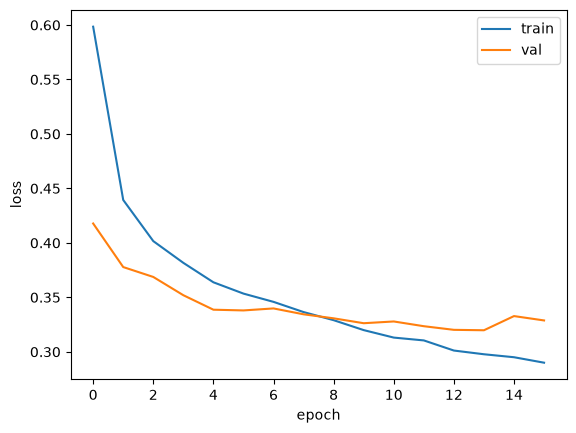

In [56]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

In [57]:
model.evaluate(val_scaled, val_target)

375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 578us/step - accuracy: 0.8836 - loss: 0.3198


[0.3197893798351288, 0.8835833072662354]